11/1/2026 Gottlieb

In the last notebook we dicussed the theory behind Vásquez and Farinelli's algorithm, with an example for an ideal case. The purpose of this notebook is to implement their algorithm by working through an example of 3 assets. In the next notebook we will then apply the methods produced to recreate their 21-asset simulation.

But before we estimate anything from prices, let's rebuild the objects from the previous notebook to give us a known answer to test against later. We use 3 assets: cash and two risky assets. The model is simplified so that both risky assets have exposure 1 to the same Brownian shock, while cash has exposure 0:
$$\sigma = (0,1,1)^T, \qquad J = \frac{1}{\sqrt{2}}(0,1,-1)^T$$

Here $J$ (see Eq. 20) gives normalized dollar positions: long Asset 1 and short Asset 2. Further, its entries sum to zero, its length is one, and its exposure to the shared shock is zero:
$$J^T\mathbf{1}=0, \qquad J^TJ=1, \qquad J^T\sigma=0$$

The theoretical covariance per unit time is $\Omega = \sigma\sigma^T$ and we enforce the zero-cost constraint using the following:
$$P=I-\frac{1}{N}U, \qquad G=P\Omega P$$

This expression for $G$ is the compact equivalent of (Eq. 13) where $U$ is the matrix of all ones. We find the variance of a particular vector to be $J^T\Omega J$. Our chosen $J$ has exactly zero variance. Also, the all-ones vector is a zero mode of $G$, but it is not a zero-cost portfolio and therefore must be excluded.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
assets = ["Cash", "Asset 1", "Asset 2"]
N = len(assets)
ones = np.ones(N)
U = np.outer(ones, ones)
sigma = np.array([0.0, 1.0, 1.0])
J = np.array([0.0, 1.0, -1.0]) / np.sqrt(2)

Omega = np.outer(sigma, sigma)
P = np.eye(N) - U / N
G = P @ Omega @ P

print("Covariance matrix (Omega):")
print(pd.DataFrame(Omega, index=assets, columns=assets))
print("\nProjected covariance (G):")
print(pd.DataFrame(G, index=assets, columns=assets).round(3))
print("\nJ =", np.round(J, 3))
print(f"Sum of positions: {J @ ones:.6f}")
print(f"Length of J: {np.linalg.norm(J):.6f}")
print(f"Shared-shock exposure: {J @ sigma:.6f}")
print(f"Portfolio variance: {J @ Omega @ J:.6f}")
print("\nG @ J =", np.round(G @ J, 10))
print("G @ ones =", np.round(G @ ones, 10))
print("Eigenvalues of G:", np.round(np.linalg.eigvalsh(G), 6))

Covariance matrix (Omega):
         Cash  Asset 1  Asset 2
Cash      0.0      0.0      0.0
Asset 1   0.0      1.0      1.0
Asset 2   0.0      1.0      1.0

Projected covariance (G):
          Cash  Asset 1  Asset 2
Cash     0.444   -0.222   -0.222
Asset 1 -0.222    0.111    0.111
Asset 2 -0.222    0.111    0.111

J = [ 0.     0.707 -0.707]
Sum of positions: 0.000000
Length of J: 1.000000
Shared-shock exposure: 0.000000
Portfolio variance: 0.000000

G @ J = [0. 0. 0.]
G @ ones = [-0.  0.  0.]
Eigenvalues of G: [-0.        0.        0.666667]


From these results take notice of the eigenvalues of $G$. Of the zero eigenvalues, one belongs to the trivial all-ones direction, and the other our zero-cost, zero-variance portfolio direction $J$. The remaining eigenvalue is not important.

An eigenvalue of zero variance does not establish arbitrage. We also need a nonzero drift along this null direction (this will be established very soon).

However, we've made the simplication that both risky assets share the same shock. If we were to give each risky asset its own indepedent noise, then there is no zero-cost portfolio that cancels every shock. The smallest admissible eigenvalue is now positive (exclusing the trivial mode). The detector we will recreate uses a finite window of prices to estimate $\hat\Omega$, construct $\hat G$, and select the lowest variance directions $\hat J$.

With the recap out of the way let's simulate the returns of 3 assets with a known drift. We will keep the exact shared-shock model from above (no indepedent noise). The return of an asset per unit time is defined as (Eq. 2), with one shared shock:
$$\frac{dX_\mu}{X_\mu}=\alpha_\mu\,dt+\sigma_\mu\,dW$$

To make the answer known in advance, let's choose an annualized drift of $m = 0.04$ along $J$ (this is our arbitrage) and start both risky assets with a common drift $b = 0.05$:
$$\alpha=(0,b,b)^T+mJ$$

This is our choice of simulation parameters. From this we find that the drift along the null direction is:
$$\alpha_J=J^T\alpha=m=0.04$$

For our model, cash stays at 1 and the risky assets start a 100. We will measure time in years and use $\Delta t = 1/252$ so that each step represents one trading day. We retain the previous example's volatility exposures.

For our model consider the exact formula for geometric Brownian motion, which is the constant-coefficient solution of (Eq. 2):
$$X_\mu(t+\Delta t)=X_\mu(t)\exp\!\left[\left(\alpha_\mu-\frac12\sigma_\mu^2\right)\Delta t+\sigma_\mu\Delta W_t\right]$$

Where $\Delta W_t\sim N(0,\Delta t)$. Additionally, we produce one Brownian increment per day and use it for both risky assets. The $-\sigma_\mu^2/2$ term converts the price drift to log-price drift.

Lastly, know the difference between simple and log returns. A simple return is the percentage price change:
$$R_t = \frac{P_t - P_{t-1}}{P_{t-1}} = (\frac{P_t}{P_{t-1}})-1$$
While a log return is:
$$\ell_t = \ln(\frac{P_t}{P_{t-1}}) = \ln(1 + R_t)$$
Which makes use of the natural logarith. For a move from 100 to 102, these are $0.02$ and approximately $0.0198$. These values are close for small moves. Log returns add across consecutive time steps, making cumulative log returns convenient for generating prices. This is why Vásquez and Farinelli use log returns in their algorithm.

In [3]:
rng = np.random.default_rng(42)
n_steps = 252
dt = 1 / 252
base_drift = 0.05
added_drift = 0.04

alpha = np.array([0.0, base_drift, base_drift]) + added_drift * J
init_prices = np.array([1.0, 100.0, 100.0])

dW = rng.normal(loc=0.0, scale=np.sqrt(dt), size=n_steps)

log_returns = (alpha - 0.5 * sigma**2) * dt + dW[:, None] * sigma[None, :]
log_growth = np.vstack([np.zeros(N), np.cumsum(log_returns, axis=0)])

prices = pd.DataFrame(
    init_prices * np.exp(log_growth),
    index=pd.RangeIndex(n_steps + 1, name="Day"),
    columns=assets,
)

print("Model parameters:")
print(pd.DataFrame({"Drift (alpha)": alpha, "Exposure (sigma)": sigma}, index=assets).round(6))
print(f"\nDrift along J: {J @ alpha:.6f}")
print("\nPrice observations:")
print(prices.head(6).round(4))


Model parameters:
         Drift (alpha)  Exposure (sigma)
Cash          0.000000               0.0
Asset 1       0.078284               1.0
Asset 2       0.021716               1.0

Drift along J: 0.040000

Price observations:
     Cash   Asset 1   Asset 2
Day                          
0     1.0  100.0000  100.0000
1     1.0  101.7676  101.7448
2     1.0   95.1549   95.1122
3     1.0   99.5944   99.5274
4     1.0  105.4970  105.4023
5     1.0   93.1402   93.0357


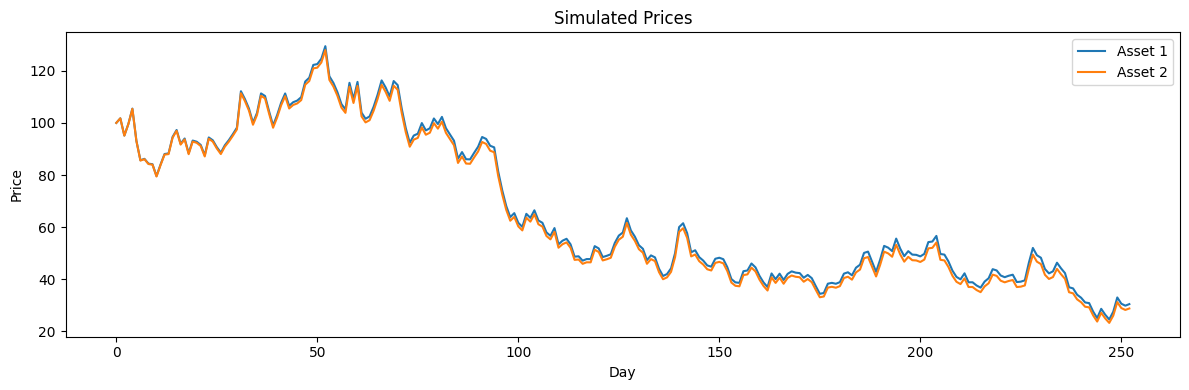

In [4]:
fig, ax = plt.subplots(1, 1, figsize=(12, 4))

ax.plot(prices.index, prices["Asset 1"], label="Asset 1")
ax.plot(prices.index, prices["Asset 2"], label="Asset 2")
ax.set_title("Simulated Prices")
ax.set_xlabel("Day")
ax.set_ylabel("Price")
ax.legend()

plt.tight_layout()
plt.show()


Briefly, Vásquez and Farinelli detector (outlined in section 4.1) estimates low-variance, zero-cost portfolios from past prices, measures their next return, and multiples consecutive drift estimates. For our 3 assets, we use one direction ($k=1$) and a 60 day return window ($L=60$). From this, the algorithm is defined as follows:
1. Starting with assets $X_{\mu}, \mu = 0,1,...,N-1$, estimate the covariance matrix $\hat\Omega_{\mu\nu}(t)$ (Eq. 93) from the window's log returns on the interval $[t, t-L]$
2. Construct the matrix $\hat G$ (Eq. 85), extract its orthonormal eigenvectors $\hat J^A, A=0,1,...,N-1$ (Eq. 86), and rank in order of increasing eigenvalues (Eq. 87)
3. Given a guess at dimension of the null space $k=dim(\mathcal{N})$, take its basis to be the eigenvectors of $\hat G$ up to $k^{th}$ vector, $\hat J^A, A=0,1,...,k$
4. Measure the returns $\hat\alpha^A(t+1)$ over the next day (Eq. 89)
5. Move the time window forward and repeat the previous steps so there is more than one estimate for $\hat\alpha^A$, then calculate the arbitrage estimator $\mathcal{\hat A}^2$ by multiplying consecutive drifts (Eq. 90)
6. Repeat all previous steps with each asset $X_\mu$ as numéraire to check for gauge invariance

Let's understand this algorithm in sequence. (Eq. 93) is the paper's covariance estimator:
$$\ell_{\mu,t} = \ln[\frac{X_\mu(t)}{X_\mu(t-1)}], \qquad \hat\Omega_{\mu\nu}(t)=\frac1L\sum_{i=0}^{L-1}\ell_{\mu,t-i}\ell_{\nu,t-i}-\frac1{L^2}\sum_{i,j=0}^{L-1}\ell_{\mu,t-i}\ell_{\nu,t-j}$$

Each entry of $\hat \Omega$ concerns one pair of assets, $\mu$ and $\nu$, using their log returns over the same $L$ dates. This equation can be understood as the average product minus the product of averages. Specifically, the first term multiplies the log returns of the assets and then takes their average. The second term can be broken apart so that it takes the average of each assets log return separately and then multiplies. Well, why does this work? This is because covariance measures whether assets move together relative to their own averages. With this definition established, let's rewrite (Eq. 93) to follow the usual definition of sample covariance:

$$\hat \Omega_{\mu\nu} = \frac{1}{L}\sum_{t=1}^{L}(\ell_{\mu,t} - \bar\ell_{\mu})(\ell_{\nu,t} - \bar\ell_{\nu})$$

This formula expands to our established defintion from above. Let's now convert this to equation to a linear algebraic expression. We'll start by allocating those deviations into a matrix $R$ with dates as rows and assets as columns:
$$R_{t\mu} = \ell_{\mu,t} - \bar\ell_{\mu}, \qquad R_{t\nu} = \ell_{\nu,t} - \bar\ell_{\nu}$$

Therefore with matrix multiplication we arrive at the following result equivalent to (Eq. 93):
$$\hat\Omega_{\mu\nu} = \frac{1}{L}\sum_{t=1}^{L}R_{t\mu}R_{t\nu} = \frac{R^TR}{L}$$

In [5]:
L = 60
log_returns = np.log(prices / prices.shift(1)).iloc[1:]

def estimate_covariance(window):
    R = (window - window.mean()).to_numpy()
    return R.T @ R / len(window)

Omega_hat = estimate_covariance(log_returns.iloc[:L])
print(f"Estimation window: Days 1-{L}")
print("Estimated covariance per daily step:")
print(pd.DataFrame(Omega_hat, index=assets, columns=assets).round(6))

Estimation window: Days 1-60
Estimated covariance per daily step:
         Cash   Asset 1   Asset 2
Cash      0.0  0.000000  0.000000
Asset 1   0.0  0.002409  0.002409
Asset 2   0.0  0.002409  0.002409


The next step is to construct matrix $\hat G$ from (Eq. 85):
$$\hat G=\hat\Omega-\frac1N(U\hat\Omega+\hat\Omega U)+\frac1{N^2}\operatorname{Tr}(U\hat\Omega)U$$

From this we extract orthonormal eigenvectors (Eq. 86):
$$\hat G\hat J^A=\lambda^A\hat J^A, \qquad (\hat J^A)^T\hat J^B=\delta^{AB}, \qquad A,B=0,1,...,N-1$$

In the previous notebook we saw that (Eq. 85) is equivalent to the following expression:
$$\hat G = P\hat\Omega P, \qquad P = I - \frac{1}{N}U$$

We can solve for (Eq. 86) directly using `np.linalg.eigh(G_hat)`, which returns eigenvalues in increasing order. The paper labels the trivial direction $\hat J^0$ and excludes it when selecting $A=1,2,...,k$. To sort out the trivial vector we will subtract each candidate by its average entry. With this method, the trivial vector becomes zero and is skipped. Otherwise, the remaining vectors are normalized and the first surviving candidate is extracted. For our example we only need one direction ($k=1$).

In [6]:
def estimate_direction(window):
    Omega_hat = estimate_covariance(window)
    G_hat = P @ Omega_hat @ P
    G_hat = (G_hat + G_hat.T) / 2
    eigenvalues, eigenvectors = np.linalg.eigh(G_hat)

    for vector in eigenvectors.T:
        candidate = vector - vector.mean()
        length = np.linalg.norm(candidate)
        if length > 1e-8:
            return candidate / length

    raise ValueError("No nontrivial zero-cost direction was found.")

J_hat = estimate_direction(log_returns.iloc[:L])
if J_hat[1] < 0: J_hat = -J_hat

print(pd.DataFrame({"Known J": J, "Estimated J": J_hat}, index=assets).round(6))

          Known J  Estimated J
Cash     0.000000     0.000000
Asset 1  0.707107     0.707107
Asset 2 -0.707107    -0.707107


Now that we have our lowest variance direction, we measure the return of the next day (Eq. 89):
$$\hat\alpha^A(t+\Delta t) = \sum_\mu\frac{\hat J^A_\mu(t)}{\Delta t\,X_\mu(t)} \left[X_\mu(t+\Delta t)-X_\mu(t)\right]$$

Notice this formula contains a simple return and therefore we can compute it as `J_hat @ simple_return / dt`. We then move a time step forward and repeat the previous steps to estimate the next $\hat\alpha^A$. The arbitrage detector is defined in (Eq. 90):
$$\hat{\mathcal A^2}(t+\Delta t) = \sum_{A=1}^k[\hat\alpha^A(t)]^2 + \sum_{A=1}^k\hat\alpha^A(t) \left[\hat\alpha^A(t+\Delta t)-\hat\alpha^A(t)\right]$$

With $k=1$ (solving for one low-variance direction) the equation is simply:
$$\hat{\mathcal A^2}(t+\Delta t) = \hat\alpha(t)\hat\alpha(t+\Delta t)$$

In [7]:
def run_detector(price_data, L, dt):
    log_r = np.log(price_data / price_data.shift(1)).iloc[1:]
    simple_r = (price_data / price_data.shift(1) - 1).iloc[1:]
    previous_J = None
    drift_estimates = []
    directions = []

    for i in range(L, len(log_r)):
        window = log_r.iloc[i - L:i]
        current_J = estimate_direction(window)

        if previous_J is None:
            if current_J[1] < 0: current_J = -current_J
        elif current_J @ previous_J < 0:
            current_J = -current_J

        alpha_hat = current_J @ simple_r.iloc[i].to_numpy() / dt
        drift_estimates.append(alpha_hat)
        directions.append(current_J)
        previous_J = current_J

    result = pd.DataFrame(
        {"Estimated drift": drift_estimates},
        index=log_r.index[L:],
    )

    result["Detector"] = result["Estimated drift"].shift(1) * result["Estimated drift"]
    result["Running mean"] = result["Detector"].expanding().mean()
    weights = pd.DataFrame(directions, index=result.index, columns=price_data.columns)
    return result, weights

results, estimated_positions = run_detector(prices, L, dt)
added_drift_squared = added_drift**2

print(results.head(6).round(6))

print(f"\nAdded drift: {added_drift:.6f}")
mean_drift_value = results['Estimated drift'].mean()
print(f"Mean drift value: {mean_drift_value:.6f}")

print(f"\nAdded drift squared: {added_drift_squared:.6f}")
mean_detector_value = results['Detector'].mean()
print(f"Mean detector value: {mean_detector_value:.6f}")

     Estimated drift  Detector  Running mean
Day                                         
61          0.035912       NaN           NaN
62          0.039095  0.001404      0.001404
63          0.040340  0.001577      0.001491
64          0.041431  0.001671      0.001551
65          0.041758  0.001730      0.001596
66          0.041975  0.001753      0.001627

Added drift: 0.040000
Mean drift value: 0.039794

Added drift squared: 0.001600
Mean detector value: 0.001585


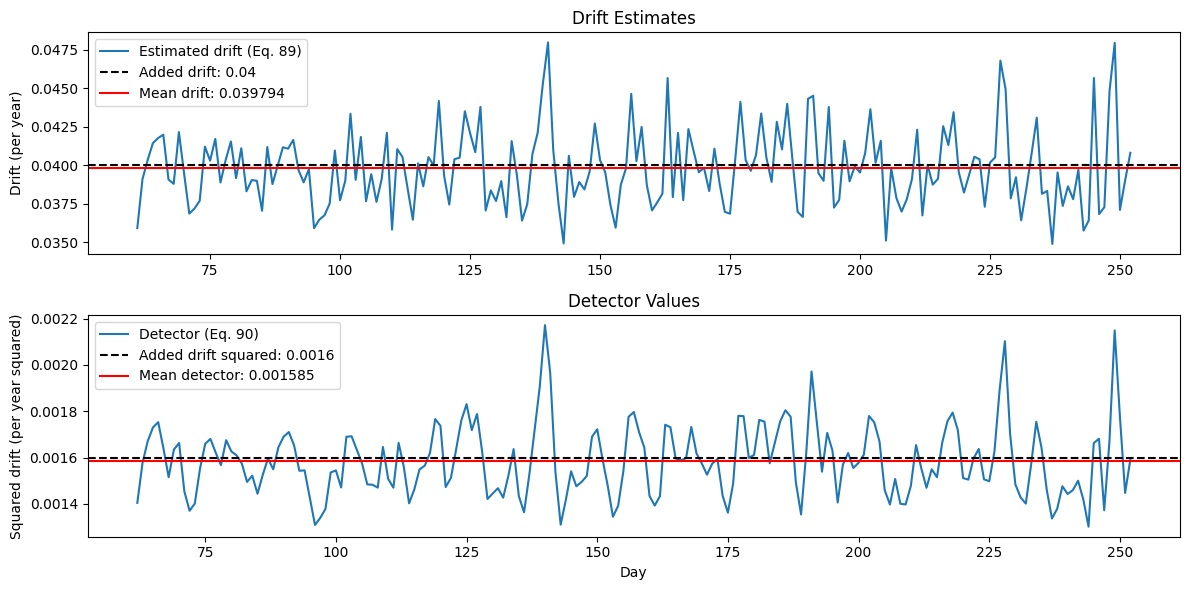

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6))

axes[0].plot(results.index, results["Estimated drift"], label="Estimated drift (Eq. 89)")
axes[0].axhline(added_drift, c="k", linestyle="--", label="Added drift: 0.04")
axes[0].axhline(mean_drift_value, c="r", linestyle="-", label=f"Mean drift: {mean_drift_value:.6f}")
axes[0].set_title("Drift Estimates")
axes[0].set_ylabel("Drift (per year)")
axes[0].legend()

axes[1].plot(results.index, results["Detector"], label="Detector (Eq. 90)")
axes[1].axhline(added_drift_squared, c="k", linestyle="--", label="Added drift squared: 0.0016")
axes[1].axhline(mean_detector_value, c="r", linestyle="-", label=f"Mean detector: {mean_detector_value:.6f}")
axes[1].set_title("Detector Values")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("Squared drift (per year squared)")
axes[1].legend()

plt.tight_layout()
plt.show()

The final step is to repeat the process in different pricing units to check for what Vásquez and Farinelli call gauge invariance. A numéraire is the asset used as the pricing unit. For each asset $q$, replace every price by $X_{\mu} / X_q$ and rerun the same detector. Here, close mean signals across units support robustness, the finite step estimate do not need to agree exactly.

In [9]:
mean_signals = {}
for numeraire in assets:
    relative_prices = prices.div(prices[numeraire], axis=0)
    relative_results, _ = run_detector(relative_prices, L, dt)
    mean_signals[numeraire] = relative_results["Detector"].mean()

numeraire_check = pd.DataFrame.from_dict(
    mean_signals, orient="index", columns=["Mean detector"]
)
numeraire_check.index.name = "Pricing unit"
numeraire_check["Added drift squared"] = added_drift_squared
print(numeraire_check.round(6))

              Mean detector  Added drift squared
Pricing unit                                    
Cash               0.001585               0.0016
Asset 1            0.001600               0.0016
Asset 2            0.001600               0.0016


The next part will extend the same calculations to the paper's 21-asset simulation.
